In [1]:
import re
from pathlib import Path

import joblib
import numpy as nps
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
DATA_FILE = Path("../datasets/spam.csv")

if not DATA_FILE.exists():
    raise FileNotFoundError(
        "datasets/spam.csv not found. Download 'SMS Spam Collection Dataset' from Kaggle "
        "and place spam.csv inside the datasets/ folder."
    )

# Kaggle's spam.csv is latin-1 encoded and has 3 extra empty columns -> keep only first two
df = pd.read_csv(DATA_FILE, encoding="latin-1", usecols=[0, 1])
df.columns = ["label", "text"]

df = df.dropna().drop_duplicates().reset_index(drop=True)
df["is_spam"] = (df["label"] == "spam").astype(int)
print(df.shape)
df.head()

(5169, 3)


,label,text,is_spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [3]:
print(df["label"].value_counts())
df["length"] = df["text"].str.len()
df.groupby("label")["length"].describe()

label
ham     4516
spam     653
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4516.0,70.459256,56.358207,2.0,34.0,52.0,90.0,910.0
spam,653.0,137.891271,30.137753,13.0,132.0,149.0,157.0,224.0


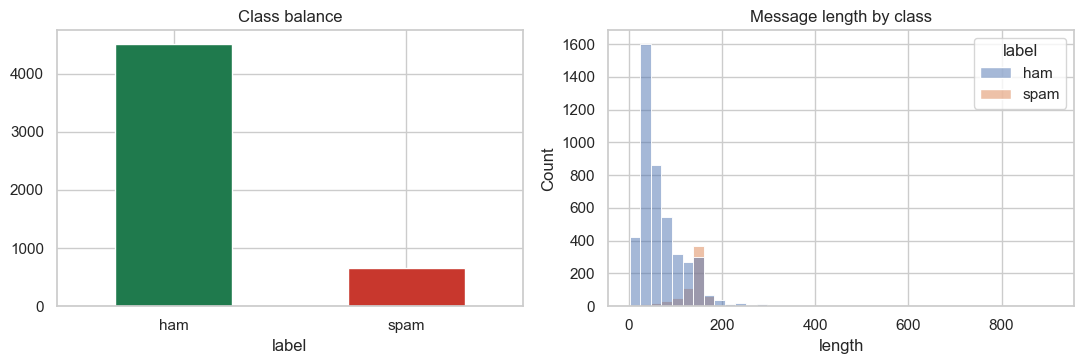

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df["label"].value_counts().plot.bar(ax=ax[0], color=["#1f7a4d", "#c8372d"], rot=0)
ax[0].set_title("Class balance")
sns.histplot(data=df, x="length", hue="label", bins=40, ax=ax[1])
ax[1].set_title("Message length by class")
plt.tight_layout(); plt.show()

In [6]:
## Clean the text
#Lowercase, replace URLs and long numbers with tokens (strong spam signals), strip punctuation.

In [7]:
def clean_text(text: str) -> str:
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " urltoken ", text)
    text = re.sub(r"\d{5,}", " longnumber ", text)
    text = re.sub(r"[^a-z0-9£$\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["clean"] = df["text"].apply(clean_text)
df[["text", "clean"]].head()

,text,clean
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["is_spam"], test_size=0.2, stratify=df["is_spam"], random_state=RANDOM_STATE)
print(len(X_train), len(X_test))

4135 1034


In [9]:
## Baseline: always predict "not spam"
#Any real model must beat this.

In [10]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_pred = baseline.predict(X_test)
print("Baseline accuracy:", round(accuracy_score(y_test, base_pred), 4))
print("Baseline spam recall:", recall_score(y_test, base_pred))

Baseline accuracy: 0.8733
Baseline spam recall: 0.0


In [12]:
## TF-IDF + models
#TF-IDF converts each message into a vector of word weights. Rare, informative words (like "prize") score higher than common ones. We compare Naive Bayes and Logistic Regression.

In [13]:
def make_tfidf():
    return TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)

models = {
    "MultinomialNB": MultinomialNB(alpha=0.1),
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced", C=10),
}

results, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([("tfidf", make_tfidf()), ("clf", clf)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    results.append({"model": name,
                    "accuracy": accuracy_score(y_test, pred),
                    "precision": precision_score(y_test, pred),
                    "recall": recall_score(y_test, pred),
                    "f1": f1_score(y_test, pred)})

pd.DataFrame(results).set_index("model").round(4)

,accuracy,precision,recall,f1
model,,,,
MultinomialNB,0.9874,0.9758,0.9237,0.9490
LogisticRegression,0.9865,0.9680,0.9237,0.9453


In [14]:
## Honest evaluation
#- **Precision**: of the messages flagged spam, how many really were spam? (low precision = real messages get blocked)
#- **Recall**: of all real spam, how much did we catch?

Best model: MultinomialNB 

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.98      0.92      0.95       131

    accuracy                           0.99      1034
   macro avg       0.98      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



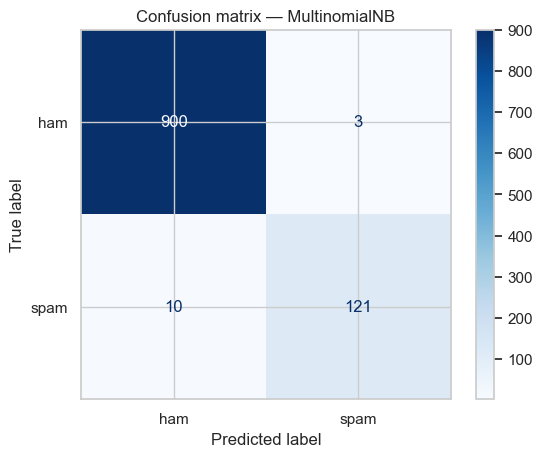

In [15]:
best_name = max(results, key=lambda r: r["f1"])["model"]
best = fitted[best_name]
pred = best.predict(X_test)
print("Best model:", best_name, "\n")
print(classification_report(y_test, pred, target_names=["ham", "spam"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["ham", "spam"]).plot(cmap="Blues")
plt.title(f"Confusion matrix — {best_name}"); plt.show()

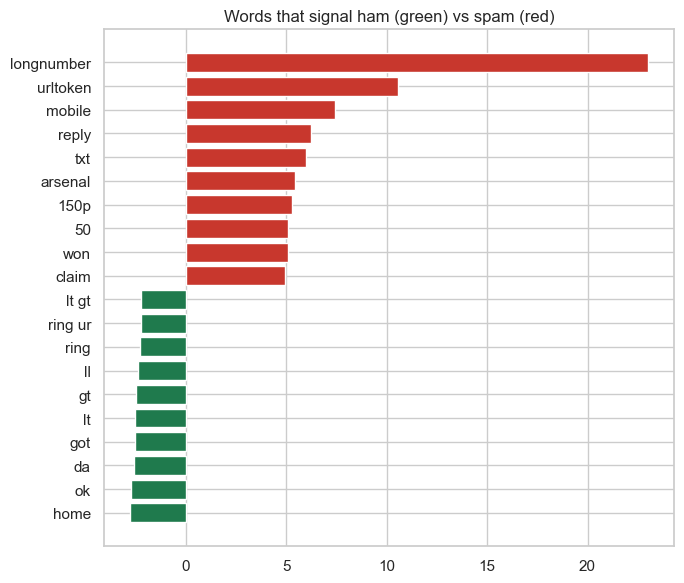

In [16]:
lr = fitted["LogisticRegression"]
vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coef = lr.named_steps["clf"].coef_[0]
top = pd.DataFrame({"word": vocab, "weight": coef}).sort_values("weight")
view = pd.concat([top.head(10), top.tail(10)])
plt.figure(figsize=(7, 6))
plt.barh(view["word"], view["weight"], color=["#1f7a4d"] * 10 + ["#c8372d"] * 10)
plt.title("Words that signal ham (green) vs spam (red)"); plt.tight_layout(); plt.show()

In [17]:
my_messages = [
    "Hey, are we still meeting for lunch at 1pm tomorrow?",
    "WINNER!! You have been selected for a £1000 cash prize. Call 09061701461 now!",
    "Your OTP for login is 482910. Do not share it with anyone.",
    "Free entry in our weekly draw! Text WIN to 80085 to claim your reward",
    "Can you send me the project report before the meeting?",
    "URGENT! Your account will be blocked. Click http://bit.ly/verify-now",
    "Mom called, please call her back when you are free",
]
probs = best.predict_proba([clean_text(m) for m in my_messages])[:, 1]
out = pd.DataFrame({"message": my_messages, "spam_probability": probs.round(3),
                    "verdict": np.where(probs >= 0.5, "SPAM", "ham")})
pd.set_option("display.max_colwidth", 80)
out

,message,spam_probability,verdict
0,"Hey, are we still meeting for lunch at 1pm tomorrow?",0.001,ham
1,WINNER!! You have been selected for a £1000 cash prize. Call 09061701461 now!,1.000,SPAM
2,Your OTP for login is 482910. Do not share it with anyone.,0.308,ham
3,Free entry in our weekly draw! Text WIN to 80085 to claim your reward,1.000,SPAM
4,Can you send me the project report before the meeting?,0.003,ham
5,URGENT! Your account will be blocked. Click http://bit.ly/verify-now,0.974,SPAM
6,"Mom called, please call her back when you are free",0.007,ham


In [18]:
joblib.dump(best, "../backend/spam_model.joblib")
print("Saved ->", Path("../backend/spam_model.joblib").resolve())

Saved -> C:\Users\Hp\AI&ML_Intership_project\AI_build_projects\P1_sms-Spam-Detector\backend\spam_model.joblib


In [19]:
## Conclusion
#- The model clearly beats the *always not-spam* baseline, especially on spam recall.
#- Accuracy alone is not enough on imbalanced data, so precision, recall and F1 are reported.
#- Limitations: the dataset is small and mostly 2000s-era UK/Singapore English. Modern spam (OTP phishing, regional languages) may need new data.
#- Next steps: cross-validation, hyperparameter search, more data.